# Implicit ALS

Train on the verified temporal split using only plays before 2018-01-01. The interaction loader supplies the factor row order for every eligible user and training track, including tracks without tags.

## Objective and training

For the aggregated play count $r_{ui}$, define preference $p_{ui}=\mathbf{1}[r_{ui}>0]$ and confidence $c_{ui}=1+10r_{ui}$. The regularized objective fits user vectors $x_u$ and track vectors $y_i$.

$$
\min_{X,Y}\sum_{u,i}c_{ui}(p_{ui}-x_u^\top y_i)^2+\lambda\left(\sum_u\|x_u\|_2^2+\sum_i\|y_i\|_2^2\right)
$$

Each ALS iteration fixes the track vectors while updating user vectors, then fixes the user vectors while updating track vectors. The CPU solver uses conjugate gradient for these updates. Positive entries carry their full confidence in CSR. Missing entries have preference 0 and unit confidence. The library's `alpha` stays at 1 because the input already contains the confidence weights. [Hu, Koren, and Volinsky (2008)](https://yifanhu.net/PUB/cf.pdf)

In [1]:
from pathlib import Path
import sys

from IPython.display import Markdown, display

root = Path.cwd()
if not (root / "pyproject.toml").is_file():
    root = root.parent
sys.path.insert(0, str(root))

from scripts.models.als import ALS_FILES, train_als, verify_als_export

model_dir = root / "data/models"
als_paths = [model_dir / name for name in ALS_FILES]
if any(path.exists() or path.is_symlink() for path in als_paths):
    run, _ = verify_als_export(model_dir)
else:
    run = train_als(root=root, show_progress=False)
display(Markdown(
    f"**CPU fit with implicit {run['implicit_version']}**. "
    f"{run['factors']} factors, regularization {run['regularization']:g}, "
    f"confidence scale {run['confidence_scale']:g}, {run['iterations']} iterations, "
    f"seed {run['random_seed']}. "
    f"Training took **{run['training_seconds']:.2f} s**, measured around the library's fit call."
))

**CPU fit with implicit 0.7.3**. 64 factors, regularization 0.1, confidence scale 10, 15 iterations, seed 42. Training took **115.69 s**, measured around the library's fit call.

## Factor dimensions and norms

Read the exported factors to measure their storage and compare user and track L2 norms. The Parquet sizes include IDs and file metadata.

| Factors | Shape | Float32 payload (MiB) | Parquet (MiB) | Norm p5 | Norm median | Norm p95 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| User | 105,578 × 64 | 25.78 | 24.85 | 6.822 | 22.944 | 38.393 |
| Track | 49,393 × 64 | 12.06 | 12.44 | 0.015 | 0.052 | 0.077 |

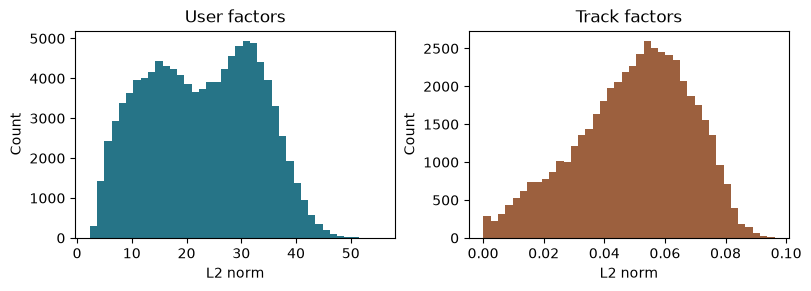

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq

model_dir = root / "data/models"
summary = [
    "| Factors | Shape | Float32 payload (MiB) | Parquet (MiB) | Norm p5 | Norm median | Norm p95 |",
    "| --- | ---: | ---: | ---: | ---: | ---: | ---: |",
]
fig, axes = plt.subplots(1, 2, figsize=(8, 2.8), layout="constrained")
for entity, ax, color in zip(("user", "track"), axes, ("#267487", "#9c603e")):
    path = model_dir / f"als_{entity}_factors.parquet"
    column = pq.read_table(path, columns=["factors"])["factors"].combine_chunks()
    vectors = column.values.to_numpy().reshape(len(column), column.type.list_size)
    norms = np.linalg.norm(vectors, axis=1)
    p5, median, p95 = np.percentile(norms, [5, 50, 95])
    rows, dimensions = vectors.shape
    summary.append(
        f"| {entity.title()} | {rows:,} × {dimensions} | {vectors.nbytes / 2**20:.2f} | "
        f"{path.stat().st_size / 2**20:.2f} | {p5:.3f} | {median:.3f} | {p95:.3f} |"
    )
    ax.hist(norms, bins=40, color=color)
    ax.set(title=f"{entity.title()} factors", xlabel="L2 norm", ylabel="Count")

display(Markdown("\n".join(summary)))
plt.show()
plt.close(fig)

## Collaborative mapping

ALS learns a track vector from training plays, so a cold-start track has no fitted ALS vector. Ridge predicts its vector from tags in the existing vocabulary. Let $X$ be the sparse TF-IDF matrix for training tracks with nonzero features, $V$ the ALS track factors selected with the same row mask, and $W$ the feature-by-latent coefficient matrix.

$$
\min_W \|XW-V\|_F^2+\lambda\|W\|_F^2
$$

The mapping has no intercept. It predicts $\hat V_{\mathrm{eval}}=X_{\mathrm{eval}}W$, so a track with no usable tags has a zero vector.

## Sparse numerical solver

A dense Gram matrix $X^\top X$ would scale with the square of the vocabulary size. SciPy implements damped LSQR using products with $X$ and $X^\top$. We keep $X$ sparse, solve each latent dimension separately with damping $\sqrt{\lambda}$, and save the resulting coefficients in float32. The pipeline checks ID alignment and rejects conditioning-limit and iteration-limit termination. [SciPy LSQR source](https://github.com/scipy/scipy/blob/v1.17.1/scipy/sparse/linalg/_isolve/lsqr.py)

In [3]:
import resource

from scripts.models.ridge import generate_ridge

ridge = generate_ridge(root=root)
peak_rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
peak_rss_bytes = peak_rss if sys.platform == "darwin" else peak_rss * 1024

## Training diagnostics

Reconstruction error measures how closely the model fits the training ALS factors. Recommendation quality is measured by the validation rankings below.

Used **42,440 of 49,393** training tracks and excluded **6,953** empty rows. The sparse design has shape 42,440 × 166,737, and the target matrix has 64 columns. A dense float64 Gram matrix would require **207.1 GiB**.

Fit time was **17.16 s** with tfidf, λ = 1, atol = 1e-06, btol = 1e-06, and a 200-iteration limit. LSQR iteration counts ranged from **102 to 105** with a median of **103**. Stop counts were {2: 64}. The largest estimated regularized normal-equation residual was 0.000138.

The float32 weights have shape **166,737 × 64** and occupy **40.71 MiB**. Their Frobenius norm is **3.0358**. Training reconstruction RMSE is **0.00296** per target value.

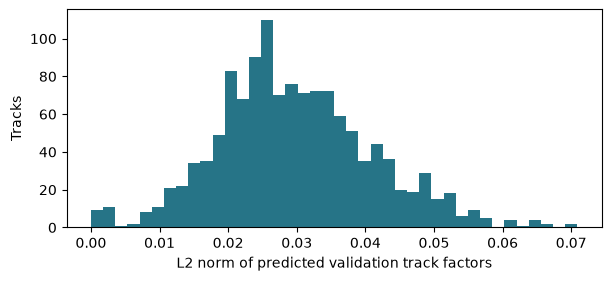

In [4]:
from collections import Counter

training = ridge["training_features"]
settings = ridge["settings"]
logs = ridge["lsqr_diagnostics"]
iterations = [entry["iterations"] for entry in logs]
stops = dict(sorted(Counter(entry["stop_code"] for entry in logs).items()))
max_normal_residual = max(entry["normal_residual_norm"] for entry in logs)
weights = np.load(model_dir / "ridge_weights.npy", mmap_mode="r")
vocabulary_size, latent_dim = weights.shape
gram_gib = vocabulary_size**2 * 8 / 2**30

display(Markdown(
    f"Used **{training['usable_tracks']:,} of {training['tracks']:,}** training tracks "
    f"and excluded **{training['zero_feature_tracks']:,}** empty rows. "
    f"The sparse design has shape {training['usable_tracks']:,} × {vocabulary_size:,}, "
    f"and the target matrix has {latent_dim} columns. A dense float64 Gram matrix would require "
    f"**{gram_gib:.1f} GiB**.\n\n"
    f"Fit time was **{ridge['training_seconds']:.2f} s** with {settings['weighting']}, "
    f"λ = {settings['regularization']:g}, atol = {settings['atol']:g}, "
    f"btol = {settings['btol']:g}, and a {settings['iter_lim']}-iteration limit. "
    f"LSQR iteration counts ranged from **{min(iterations)} to {max(iterations)}** "
    f"with a median of **{np.median(iterations):g}**. Stop counts were {stops}. "
    f"The largest estimated regularized normal-equation residual was {max_normal_residual:.3g}.\n\n"
    f"The float32 weights have shape **{vocabulary_size:,} × {latent_dim}** and occupy "
    f"**{weights.nbytes / 2**20:.2f} MiB**. Their Frobenius norm is "
    f"**{ridge['weight_frobenius']:.4f}**. Training reconstruction RMSE is "
    f"**{ridge['training_reconstruction_rmse']:.5f}** per target value."
))

column = pq.read_table(model_dir / "ridge_validation_factors.parquet")["factors"].combine_chunks()
ridge_embeddings = column.values.to_numpy().reshape(len(column), latent_dim)
embedding_norms = np.linalg.norm(ridge_embeddings, axis=1)
fig, ax = plt.subplots(figsize=(6, 2.7), layout="constrained")
ax.hist(embedding_norms, bins=40, color="#267487")
ax.set(xlabel="L2 norm of predicted validation track factors", ylabel="Tracks")
plt.show()
plt.close(fig)

## Recommendation and computational efficiency

Rank the full eligible-user pool for each validation track by $u_i^\top\hat v_j$. Track batches keep score storage bounded. The shared top-K routine breaks ties by ascending user ID, including when all scores are zero.

In [5]:
validation = ridge["evaluation"]["validation"]
display(Markdown(
    f"Predicted **{validation['tracks']:,}** track vectors, including "
    f"**{validation['zero_feature_tracks']:,}** zero-feature tracks.\n\n"
    "| Measurement | Value |\n"
    "| --- | ---: |\n"
    f"| Embedding prediction | {validation['embedding_seconds'] * 1000:.2f} ms |\n"
    f"| Scoring and top-K ranking | {validation['scoring_seconds']:.2f} s |\n"
    f"| Largest score array, measured | {validation['largest_score_block_bytes'] / 2**20:.2f} MiB |\n"
    f"| Full score array, estimated | {validation['estimated_full_score_bytes'] / 2**20:.2f} MiB |\n"
    f"| Notebook kernel peak RSS through the Ridge run | {peak_rss_bytes / 2**20:.2f} MiB |"
))

Predicted **1,274** track vectors, including **9** zero-feature tracks.

| Measurement | Value |
| --- | ---: |
| Embedding prediction | 0.18 ms |
| Scoring and top-K ranking | 0.84 s |
| Largest score array, measured | 25.78 MiB |
| Full score array, estimated | 513.10 MiB |
| Notebook kernel peak RSS through the Ridge run | 849.70 MiB |

## Validation results

Use the shared evaluator on the saved validation predictions. The three baseline files come from the baseline experiment.

In [6]:
from scripts.common.evaluate import RANK_CUTOFFS, evaluate

prediction_dir = root / "data/predictions"
prediction_files = {
    "Random": "baseline_random_validation.parquet",
    "Most Active": "baseline_most_active_validation.parquet",
    "Tag Profile": "baseline_tag_profile_validation.parquet",
    "ALS + Ridge": "ridge_validation.parquet",
}
if any(not (prediction_dir / name).is_file() for name in prediction_files.values()):
    raise FileNotFoundError("Generate missing baselines with uv run --locked python -m scripts.models.baselines --split validation.")

cutoffs = RANK_CUTOFFS
header = ["Model", *(f"Recall@{k}" for k in cutoffs), *(f"NDCG@{k}" for k in cutoffs)]
comparison = ["| " + " | ".join(header) + " |", "| --- |" + " ---: |" * (2 * len(cutoffs))]
for label, filename in prediction_files.items():
    total, zero, metrics = evaluate(prediction_dir / filename, "validation", root / "data/splits")
    _, recall, ndcg = zip(*metrics)
    comparison.append(f"| {label} | " + " | ".join(f"{value:.6f}" for value in (*recall, *ndcg)) + " |")
display(Markdown(f"**{total - zero:,}** of {total:,} validation tracks contributed.\n\n" + "\n".join(comparison)))

**1,274** of 1,274 validation tracks contributed.

| Model | Recall@100 | Recall@500 | Recall@1000 | NDCG@100 | NDCG@500 | NDCG@1000 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Random | 0.000779 | 0.005046 | 0.010405 | 0.000944 | 0.002684 | 0.004629 |
| Most Active | 0.009648 | 0.074019 | 0.134166 | 0.011070 | 0.036974 | 0.059712 |
| Tag Profile | 0.027603 | 0.107185 | 0.158301 | 0.028928 | 0.055730 | 0.075781 |
| ALS + Ridge | 0.156966 | 0.362390 | 0.475208 | 0.152254 | 0.223924 | 0.269457 |

## Test Evaluation

Run this cell after the Test Evaluation section in the [baselines notebook](03_baselines.ipynb) has produced the three baseline prediction files. This cell checks the saved ALS and Ridge fingerprints and applies the frozen mapping to the test tracks. Run this cell on its own to reuse the saved fits.

In [7]:
from pathlib import Path
import sys

from IPython.display import Markdown, display

root = Path.cwd()
if not (root / "pyproject.toml").is_file():
    root = root.parent
sys.path.insert(0, str(root))

from scripts.common.evaluate import RANK_CUTOFFS, evaluate
from scripts.models.ridge import generate_ridge

prediction_dir = root / "data/predictions"
test_predictions = {
    "Random": prediction_dir / "baseline_random_test.parquet",
    "Most Active": prediction_dir / "baseline_most_active_test.parquet",
    "Tag Profile": prediction_dir / "baseline_tag_profile_test.parquet",
}
if any(not path.is_file() for path in test_predictions.values()):
    raise FileNotFoundError("Run the Test Evaluation section in the baselines notebook first.")
generate_ridge("test", root)
test_predictions["ALS + Ridge"] = prediction_dir / "ridge_test.parquet"

header = ["Model", *(f"Recall@{k}" for k in RANK_CUTOFFS), *(f"NDCG@{k}" for k in RANK_CUTOFFS)]
rows = ["| " + " | ".join(header) + " |", "| --- |" + " ---: |" * (2 * len(RANK_CUTOFFS))]
for label, path in test_predictions.items():
    total, zero, metrics = evaluate(path, "test", root / "data/splits")
    _, recall, ndcg = zip(*metrics)
    rows.append(f"| {label} | " + " | ".join(f"{value:.6f}" for value in (*recall, *ndcg)) + " |")
display(Markdown(f"**{total - zero:,}** of {total:,} test tracks contributed.\n\n" + "\n".join(rows)))

**1,299** of 1,299 test tracks contributed.

| Model | Recall@100 | Recall@500 | Recall@1000 | NDCG@100 | NDCG@500 | NDCG@1000 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Random | 0.000678 | 0.004497 | 0.009080 | 0.000818 | 0.002404 | 0.004306 |
| Most Active | 0.012020 | 0.069816 | 0.124902 | 0.010990 | 0.035233 | 0.055696 |
| Tag Profile | 0.028827 | 0.098073 | 0.154911 | 0.028780 | 0.053430 | 0.075075 |
| ALS + Ridge | 0.139690 | 0.333068 | 0.449126 | 0.138373 | 0.209353 | 0.254699 |